# 39장 · RAG 개선안의 품질과 비용 비교

개선안을 판단하려면 같은 평가 문항에 대한 기존 방식과 후보 방식의 결과를 나란히 놓습니다. 답이 좋아졌는지와 작업량이 늘었는지를 따로 기록합니다.

재순위화를 사용하자 처리 단계가 하나 늘었습니다. 같은 질문에서 근거와 답도 바뀌었을까요? 38장의 고정 평가 자료를 재실행해 저장했던 기록을 읽고, 현재 화면에서 쓸 방법을 결정합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 기준선과 후보의 답변·출처 비교

아래 값은 제공 실험 기록의 dev-01에서 읽은 항목입니다. 자료와 질문, 후보 수 2, 최종 문서 수 1을 고정했습니다. 이 셀은 저장 기록을 대조하며 외부 모델의 응답시간을 측정하지 않습니다.


### 셀 01 · 기준선·후보의 답변 대조

baseline과 rerank의 문항 ID가 일치하는지 먼저 확인하세요.


In [1]:
baseline = {'question_id': 'dev-01',
 'answer': '도서 대출 기간은 14일입니다 [library-1:0]',
 'source_ids': ['library-1:0'],
 'rerank_calls': 0}
candidate = {'question_id': 'dev-01',
 'answer': '도서 대출 기간은 14일입니다 [library-1:0]',
 'source_ids': ['library-1:0'],
 'rerank_calls': 1}
assert baseline['question_id'] == candidate['question_id']
print(baseline['answer'] == candidate['answer'], baseline['source_ids'] == candidate['source_ids'])

True True


True가 두 개 나옵니다. 이 문항에서 답과 인용은 바뀌지 않았습니다. 다른 질문에도 동일하다고 단정하려면 문항별 기록이 필요합니다.


### 같은 문항의 결과를 한 쌍으로 비교하기

<p>두 행의 question_id가 모두 dev-01임을 assert로 확인합니다. 그래야 결과가 달라졌을 때 질문을 바꾼 영향과 검색 방법을 바꾼 영향을 혼동하지 않습니다.</p>


### 두 답변이 같다는 출력의 의미

<p>첫 번째 True는 답변 문자열이 같다는 뜻이고 두 번째 True는 출처 목록이 같다는 뜻입니다. 같은 오답을 낼 수도 있으므로 실제 정답 여부는 원문의 대출 기간 14일과 직접 대조합니다.</p>


### 과제 02 · 추가 작업량 계산

동일 문항에서 재순위 함수 호출이 몇 번 추가됐는지 계산하세요.


In [2]:
# 두 행의 rerank_calls 차이를 구하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(candidate[&#x27;rerank_calls&#x27;] - baseline[&#x27;rerank_calls&#x27;])</code></pre>
<p>실행 결과</p><pre><code>1</code></pre>
<p>한 번 더 호출했습니다. 이 값은 로컬 함수 실행 횟수여서 유료 모델 호출 횟수나 금액으로 바꿔 읽을 수 없습니다.</p>
</details>


### 추가 작업량을 비교하기

<p>baseline의 rerank_calls는 0, candidate는 1입니다. 이 차이는 추가 재정렬 횟수입니다. 시간을 재거나 요금 정보를 수집하지 않은 상태에서 이를 비용이나 지연 시간으로 환산할 수는 없습니다.</p>


## 작업량과 적용 기준 기록

저장된 결정은 개발 질문 세 건에서 이득을 찾지 못해 기준선을 유지하는 것입니다. 확인 질문에선 반납함 24시간이라는 숫자를 찾았지만 문장이 잘렸습니다. 의미가 온전한지 확인하는 작업이 남습니다.


### 시험한 후보와 실제 적용할 설정이 갈리는 지점

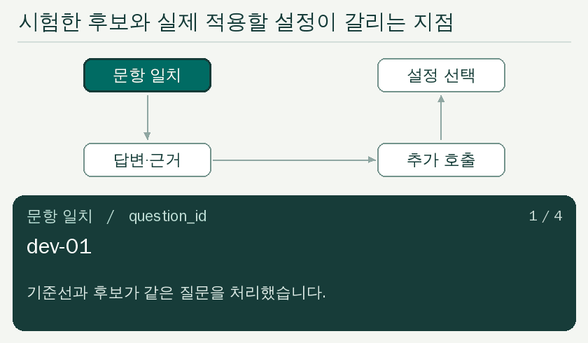

같은 dev-01에서 답변·출처·추가 호출을 차례로 대조한 뒤 적용 설정을 읽습니다.


### 셀 03 · 실험 후보와 적용 설정 구분

기록에서 두 가지 이름을 뽑으세요.

셀 01에서 직접 읽은 것은 dev-01 한 건입니다. 후보 선택은 뒤의 개발 세 문항 기록을 함께 사용합니다. 후보명을 rerank로 적는 것과 실제 서비스 방식을 baseline으로 유지하는 것은 별개입니다. 반납함 24시간 질문은 선택 후의 확인 사례입니다.


In [3]:
decision = {'selected_candidate': 'rerank', 'adopted_method': 'baseline', 'final_k': 1}
print(decision['selected_candidate'], decision['adopted_method'])

rerank baseline


검토 후보는 rerank이고 현재 유지한 방식은 baseline입니다. 다음 화면의 엔진에는 두 번째 값을 넘깁니다. 잘린 문장을 더 길게 읽는 Parent–Child, 어휘 검색과 벡터 검색을 합치는 Hybrid는 서로 다른 다음 실험 후보입니다.


### 어떤 질문에서 결론을 얻었나요?

<p>dev-01에서 재정렬 전후의 답변과 출처가 같아도 다른 질문의 성능까지 보장되지는 않습니다. 설정을 바꿀 때는 기존에 통과하던 질문도 다시 실행해 보세요.</p>


### 선택한 후보와 실제 적용 설정

<p>selected_candidate는 이번에 평가한 방법인 rerank이고 adopted_method는 최종 유지한 baseline입니다. 이 사례에서는 답변과 출처가 같고 재정렬 호출이 한 번 더 필요했습니다.</p>


## 돌아보기

‘대출 질문 한 건에서 같다’와 ‘개발 세 건을 확인해 이번엔 보류한다’는 근거 범위가 다릅니다. 팀의 실험 기록에도 판단에 사용한 문항을 적어 두세요.
